In [8]:
import sys

!{sys.executable} -m pip install numpy pandas matplotlib seaborn scikit-learn pillow plotly

  Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp314-cp314-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached thr


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load metadata CSVs (adjusting to your FASHION-DATASET folder structure)
styles_df = pd.read_csv("FASHION-DATASET/styles.csv", on_bad_lines="skip")
images_df = pd.read_csv("FASHION-DATASET/images.csv")

print("--- Styles DataFrame Shape ---")
print(styles_df.shape)
display(styles_df.head(3))

print("\n--- Images DataFrame Shape ---")
print(images_df.shape)
display(images_df.head(3))

# Verify sample image existence
sample_id = styles_df["id"].iloc[0]
sample_image_path = os.path.join(
    "FASHION-DATASET", "images", f"{sample_id}.jpg"
)
print(f"\nChecking sample image path: {sample_image_path}")
print(f"Does sample image exist? {os.path.exists(sample_image_path)}")

--- Styles DataFrame Shape ---
(44424, 10)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch



--- Images DataFrame Shape ---
(44446, 2)


,filename,link
0,15970.jpg,http://assets.myntassets.com/v1/images/style/p...
1,39386.jpg,http://assets.myntassets.com/v1/images/style/p...
2,59263.jpg,http://assets.myntassets.com/v1/images/style/p...



Checking sample image path: FASHION-DATASET\images\15970.jpg
Does sample image exist? True


In [10]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load metadata CSVs (adjusting to your FASHION-DATASET folder structure)
styles_df = pd.read_csv("FASHION-DATASET/styles.csv", on_bad_lines="skip")
images_df = pd.read_csv("FASHION-DATASET/images.csv")

print("--- Styles DataFrame Shape ---")
print(styles_df.shape)
display(styles_df.head(3))

print("\n--- Images DataFrame Shape ---")
print(images_df.shape)
display(images_df.head(3))

# Verify sample image existence
sample_id = styles_df["id"].iloc[0]
sample_image_path = os.path.join(
    "FASHION-DATASET", "images", f"{sample_id}.jpg"
)
print(f"\nChecking sample image path: {sample_image_path}")
print(f"Does sample image exist? {os.path.exists(sample_image_path)}")

--- Styles DataFrame Shape ---
(44424, 10)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch



--- Images DataFrame Shape ---
(44446, 2)


,filename,link
0,15970.jpg,http://assets.myntassets.com/v1/images/style/p...
1,39386.jpg,http://assets.myntassets.com/v1/images/style/p...
2,59263.jpg,http://assets.myntassets.com/v1/images/style/p...



Checking sample image path: FASHION-DATASET\images\15970.jpg
Does sample image exist? True


--- Master Categories Distribution ---
masterCategory
Apparel           21397
Accessories       11274
Footwear           9219
Personal Care      2403
Free Items          105
Sporting Goods       25
Home                  1
Name: count, dtype: int64

--- Sub Categories Distribution (Top 10) ---
subCategory
Topwear       15402
Shoes          7343
Bags           3055
Bottomwear     2694
Watches        2542
Innerwear      1808
Jewellery      1079
Eyewear        1073
Fragrance      1011
Sandal          963
Name: count, dtype: int64


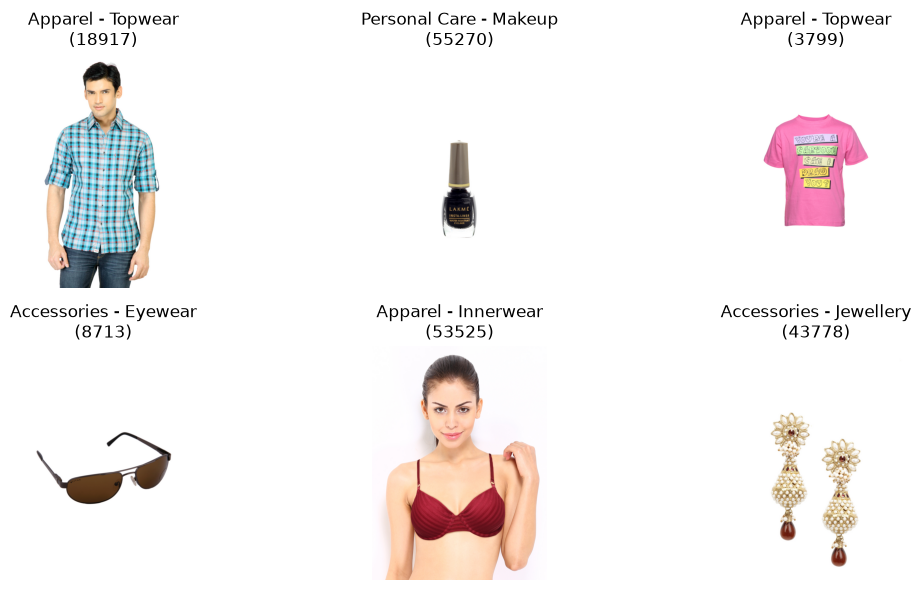

In [11]:
# 1. Let's see the breakdown of master categories (e.g., Apparel, Footwear, etc.)
print("--- Master Categories Distribution ---")
print(styles_df["masterCategory"].value_counts())

print("\n--- Sub Categories Distribution (Top 10) ---")
print(styles_df["subCategory"].value_counts().head(10))

# 2. Let's plot a quick sample grid of 6 random images to visually inspect our data
from PIL import Image

# Grab 6 random valid image IDs from our styles dataframe
sample_rows = styles_df.sample(6)

plt.figure(figsize=(12, 6))
for i, (_, row) in enumerate(sample_rows.iterrows()):
    img_id = row["id"]
    img_path = os.path.join("FASHION-DATASET", "images", f"{img_id}.jpg")

    if os.path.exists(img_path):
        img = Image.open(img_path)
        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(
            f"{row['masterCategory']} - {row['subCategory']}\n({img_id})"
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
  Using cached https://download-r2.pytorch.org/whl/cpu/torch-2.14.1%2Bcpu-cp314-cp314-win_amd64.whl.metadata (38 kB)
  Using cached https://download-r2.pytorch.org/whl/cpu/torchvision-0.29.1%2Bcpu-cp314-cp314-win_amd64.whl.metadata (5.8 kB)
  Using cached filelock-3.32.3-py3-none-any.whl.metadata (2.0 kB)
  Using cached https://download.pytorch.org/whl/setuptools-78.1.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached fsspec-2026.7.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached https://download-r2.pytorch.org/whl/cpu/torch-2.14.1%2Bcpu-cp314-cp314-win_amd64.whl (125.9 MB)
Using cached https://download-r2.pytorch.org/whl/cpu/torchvision-0.29.1%2Bcpu-cp314-cp314-win_amd64.whl (1.4 MB)
Using cached fsspec-2026.7.0-py3-none-any.whl (206 kB)
Usi


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [16]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms

# 1. Define image preprocessing pipeline for ResNet
transform = transforms.Compose(
    [
        transforms.Resize(
            (224, 224)
        ),  # Standard input size for ResNet50
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),  # ImageNet standards
    ]
)

# 2. Load Pretrained ResNet50 and remove the final classification layer
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# Strip the last linear classification layer so it outputs the 2048-dim embedding vector
feature_extractor = nn.Sequential(*list(model.children())[:-1])
feature_extractor.eval()  # Set to evaluation mode (crucial for inference)

print("ResNet50 feature extractor loaded successfully on CPU!")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\DELL/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100.0%


ResNet50 feature extractor loaded successfully on CPU!


In [18]:
%pip install tqdm

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
import numpy as np
from tqdm import tqdm

# 1. Take a controlled random sample of 1,000 items to keep processing smooth and fast
subset_df = styles_df.sample(n=1000, random_state=42).reset_index(drop=True)

embeddings = []
valid_ids = []

print("Starting feature extraction on 1,000 fashion items...")
for idx, row in subset_df.iterrows():
    img_id = row["id"]
    img_path = os.path.join("FASHION-DATASET", "images", f"{img_id}.jpg")

    if os.path.exists(img_path):
        try:
            # Load image and convert to RGB (handles any grayscale or 4-channel PNGs safely)
            img = Image.open(img_path).convert("RGB")

            # Apply our transform pipeline and add a batch dimension -> shape: (1, 3, 224, 224)
            img_tensor = transform(img).unsqueeze(0)

            # Extract features without tracking gradients (saves memory & speeds up inference)
            with torch.no_grad():
                feature = feature_extractor(img_tensor)
                # Squeeze the tensor and convert to a NumPy array -> shape: (2048,)
                feature = feature.squeeze().numpy()

            embeddings.append(feature)
            valid_ids.append(img_id)
        except Exception as e:
            print(f"Skipping image {img_id} due to error: {e}")

# Convert list of embeddings into a final matrix
embeddings_matrix = np.array(embeddings)

print(f"\nExtraction complete!")
print(f"Successfully processed: {len(valid_ids)} images.")
print(f"Embeddings matrix shape: {embeddings_matrix.shape}")

Starting feature extraction on 1,000 fashion items...

Extraction complete!
Successfully processed: 1000 images.
Embeddings matrix shape: (1000, 2048)


In [20]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. Reduce dimensions from 2048 down to 50 using PCA (retaining core variance while speeding up clustering)
print("Running PCA dimensionality reduction...")
pca = PCA(n_components=50, random_state=42)
embeddings_pca = pca.fit_transform(embeddings_matrix)
print(f"PCA reduced shape: {embeddings_pca.shape}")
print(
    f"Explained variance ratio captured: {sum(pca.explained_variance_ratio_):.2f}"
)

# 2. Apply KMeans Clustering (let's start with 5 clusters to group different types of items)
num_clusters = 5
print(f"\nRunning KMeans clustering with {num_clusters} clusters...")
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(embeddings_pca)

# Add cluster labels back to our subset dataframe for analysis
subset_df["cluster"] = cluster_labels

print("\n--- Items per Cluster ---")
print(subset_df["cluster"].value_counts())

Running PCA dimensionality reduction...
PCA reduced shape: (1000, 50)
Explained variance ratio captured: 0.78

Running KMeans clustering with 5 clusters...

--- Items per Cluster ---
cluster
3    305
4    255
0    204
1    126
2    110
Name: count, dtype: int64


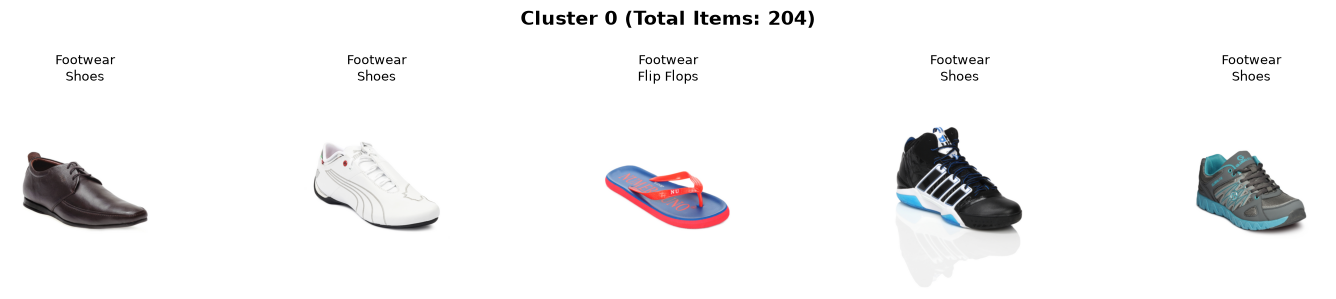

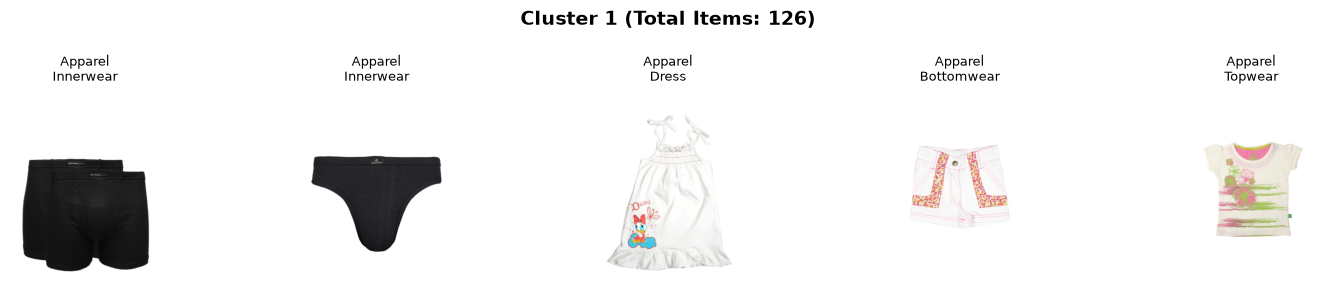

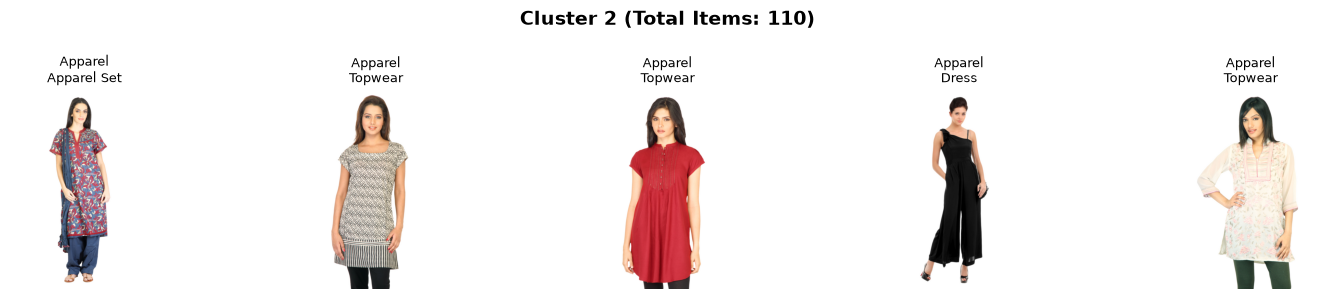

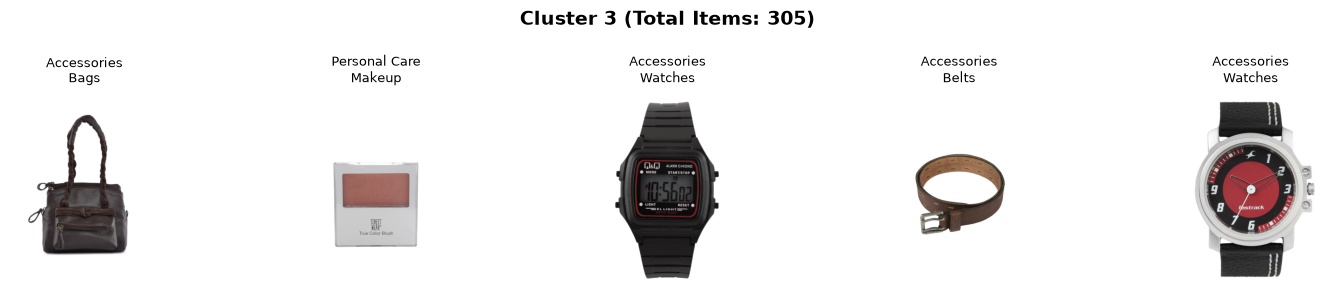

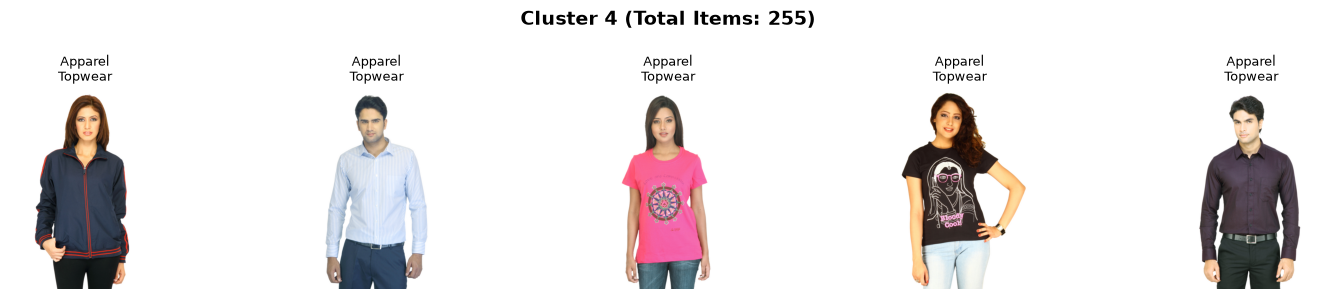

In [21]:
import matplotlib.pyplot as plt

# Loop through each cluster and plot 5 sample images
for cluster_id in sorted(subset_df["cluster"].unique()):
    cluster_items = subset_df[subset_df["cluster"] == cluster_id]
    sample_items = cluster_items.sample(
        min(5, len(cluster_items)), random_state=42
    )

    plt.figure(figsize=(15, 3))
    plt.suptitle(
        f"Cluster {cluster_id} (Total Items: {len(cluster_items)})",
        fontsize=14,
        fontweight="bold",
    )

    for i, (_, row) in enumerate(sample_items.iterrows()):
        img_id = row["id"]
        img_path = os.path.join("FASHION-DATASET", "images", f"{img_id}.jpg")

        if os.path.exists(img_path):
            img = Image.open(img_path)
            plt.subplot(1, 5, i + 1)
            plt.imshow(img)
            plt.title(
                f"{row['masterCategory']}\n{row['subCategory'][:12]}",
                fontsize=9,
            )
            plt.axis("off")

    plt.tight_layout()
    plt.show()

In [22]:
import joblib

joblib.dump(pca, "pca_model.pkl")
joblib.dump(kmeans, "kmeans_model.pkl")
subset_df.to_csv("clustered_fashion_sample.csv", index=False)